## Week 2

In [1]:
import pandas as pd
df=pd.read_csv(r"C:\Users\stuti\Downloads\jammu_synthetic_properties_with_recommendation.csv")

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 33 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Property_ID                 1200 non-null   object 
 1   Property_type               1200 non-null   object 
 2   Area_sqft                   1200 non-null   int64  
 3   Price_per_sqft              1200 non-null   int64  
 4   Asking_price_INR            1200 non-null   int64  
 5   Property_age_years          1200 non-null   int64  
 6   Corner_plot                 1200 non-null   object 
 7   Facing_direction            1184 non-null   object 
 8   Road_width_ft               1182 non-null   float64
 9   locality                    1200 non-null   object 
 10  Distance_to_city_center_km  1200 non-null   float64
 11  Distance_to_highway_km      1200 non-null   float64
 12  Locality_score              1200 non-null   float64
 13  Infrastructure_score        1200 

In [3]:
df.head()

,Property_ID,Property_type,Area_sqft,Price_per_sqft,Asking_price_INR,Property_age_years,Corner_plot,Facing_direction,Road_width_ft,locality,...,Builder_credibility_score,Civic_complaints_count,Flood_risk,Electricity_connection,Sewage_connection,Water_supply_score,Past_5yr_price_growth_pct,Data_Status,Data_Generation_Seed,Recommendation
0,JMU-00001,Independent_House,1651,5303,8755253,33,No,North-West,39.4,Bantalab,...,0.831,4,Medium,Yes,Unknown,1.000,9.80,SYNTHETIC_NOT_REAL,20261013,Not Buy
1,JMU-00002,Plot,1647,4061,6688467,9,No,South,21.1,Upper Gadigarh,...,0.502,3,Unknown,Yes,Yes,0.729,6.14,SYNTHETIC_NOT_REAL,20261013,Not Buy
2,JMU-00003,Plot,724,5494,3977656,15,No,South,24.3,Bohri,...,0.910,4,High,Yes,Yes,0.757,3.09,SYNTHETIC_NOT_REAL,20261013,Not Buy
3,JMU-00004,Apartment,1687,5297,8936039,23,No,North,14.1,Paloura,...,0.771,3,High,No,Yes,0.415,8.08,SYNTHETIC_NOT_REAL,20261013,Not Buy
4,JMU-00005,Independent_House,1426,5362,7646212,3,Yes,South-East,21.0,Talab Tillo,...,0.816,4,Low,Yes,Yes,0.765,5.44,SYNTHETIC_NOT_REAL,20261013,Not Buy


In [4]:
df=df.drop(['Data_Status','Data_Generation_Seed'],axis=1)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Property_ID                 1200 non-null   object 
 1   Property_type               1200 non-null   object 
 2   Area_sqft                   1200 non-null   int64  
 3   Price_per_sqft              1200 non-null   int64  
 4   Asking_price_INR            1200 non-null   int64  
 5   Property_age_years          1200 non-null   int64  
 6   Corner_plot                 1200 non-null   object 
 7   Facing_direction            1184 non-null   object 
 8   Road_width_ft               1182 non-null   float64
 9   locality                    1200 non-null   object 
 10  Distance_to_city_center_km  1200 non-null   float64
 11  Distance_to_highway_km      1200 non-null   float64
 12  Locality_score              1200 non-null   float64
 13  Infrastructure_score        1200 

In [6]:
df.isnull().sum()

Property_ID                    0
Property_type                  0
Area_sqft                      0
Price_per_sqft                 0
Asking_price_INR               0
Property_age_years             0
Corner_plot                    0
Facing_direction              16
Road_width_ft                 18
locality                       0
Distance_to_city_center_km     0
Distance_to_highway_km         0
Locality_score                 0
Infrastructure_score           0
Road_connectivity_score        0
Public_transport_score         0
Nearby_schools_count           0
Nearby_hospitals_count         0
Ownership_type                 0
Registry_type                  0
Jda_approved                   0
Bank_loan_approved             0
Builder_name                   0
Builder_credibility_score     14
Civic_complaints_count         0
Flood_risk                     0
Electricity_connection         0
Sewage_connection              0
Water_supply_score            18
Past_5yr_price_growth_pct     12
Recommenda

In [7]:
df.isnull().mean()*100

Property_ID                   0.000000
Property_type                 0.000000
Area_sqft                     0.000000
Price_per_sqft                0.000000
Asking_price_INR              0.000000
Property_age_years            0.000000
Corner_plot                   0.000000
Facing_direction              1.333333
Road_width_ft                 1.500000
locality                      0.000000
Distance_to_city_center_km    0.000000
Distance_to_highway_km        0.000000
Locality_score                0.000000
Infrastructure_score          0.000000
Road_connectivity_score       0.000000
Public_transport_score        0.000000
Nearby_schools_count          0.000000
Nearby_hospitals_count        0.000000
Ownership_type                0.000000
Registry_type                 0.000000
Jda_approved                  0.000000
Bank_loan_approved            0.000000
Builder_name                  0.000000
Builder_credibility_score     1.166667
Civic_complaints_count        0.000000
Flood_risk               

In [8]:
df['Facing_direction'].describe()

count      1184
unique        8
top       South
freq        166
Name: Facing_direction, dtype: object

In [9]:
df['Facing_direction'].value_counts()

Facing_direction
South         166
East          161
North-East    156
North         144
South-West    144
South-East    141
West          140
North-West    132
Name: count, dtype: int64

In [10]:
df['Facing_direction'].isnull()

0       False
1       False
2       False
3       False
4       False
        ...  
1195    False
1196    False
1197    False
1198    False
1199    False
Name: Facing_direction, Length: 1200, dtype: bool

In [11]:
from sklearn.impute import SimpleImputer
categorical_cols = [
    "Property_type",
    "Corner_plot",
    "Facing_direction",
    "locality",
    "Ownership_type",
    "Registry_type",
    "Jda_approved",
    "Bank_loan_approved",
    "Builder_name",
    "Flood_risk",
    "Electricity_connection",
    "Sewage_connection"
]

# Check missing values before imputation
print("Before imputation:")
print(df[categorical_cols].isnull().sum())

# Create the imputer
imputer = SimpleImputer(strategy="most_frequent")

# Impute missing categorical values
df[categorical_cols] = imputer.fit_transform(
    df[categorical_cols]
)

# Check missing values after imputation
print("\nAfter imputation:")
print(df[categorical_cols].isnull().sum())

# Save the processed dataset
df.to_csv("synthetic_properties_imputed.csv", index=False)

print("\nImputation completed successfully!")


Before imputation:
Property_type              0
Corner_plot                0
Facing_direction          16
locality                   0
Ownership_type             0
Registry_type              0
Jda_approved               0
Bank_loan_approved         0
Builder_name               0
Flood_risk                 0
Electricity_connection     0
Sewage_connection          0
dtype: int64

After imputation:
Property_type             0
Corner_plot               0
Facing_direction          0
locality                  0
Ownership_type            0
Registry_type             0
Jda_approved              0
Bank_loan_approved        0
Builder_name              0
Flood_risk                0
Electricity_connection    0
Sewage_connection         0
dtype: int64

Imputation completed successfully!


In [12]:
numerical_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Property_age_years",
    "Road_width_ft",
    "Distance_to_city_center_km",
    "Distance_to_highway_km",
    "Locality_score",
    "Infrastructure_score",
    "Road_connectivity_score",
    "Public_transport_score",
    "Nearby_schools_count",
    "Nearby_hospitals_count",
    "Builder_credibility_score",
    "Civic_complaints_count",
    "Water_supply_score",
    "Past_5yr_price_growth_pct"
]

# Check missing values before imputation
print("Before imputation:")
print(df[numerical_cols].isnull().sum())

# Create the numerical imputer
imputer = SimpleImputer(strategy="median")

# Impute missing numerical values
df[numerical_cols] = imputer.fit_transform(
    df[numerical_cols]
)

# Check missing values after imputation
print("\nAfter imputation:")
print(df[numerical_cols].isnull().sum())

# Save the processed dataset
df.to_csv("synthetic_properties_numerical_imputed.csv", index=False)

print("\nNumerical imputation completed successfully!")

Before imputation:
Area_sqft                      0
Price_per_sqft                 0
Property_age_years             0
Road_width_ft                 18
Distance_to_city_center_km     0
Distance_to_highway_km         0
Locality_score                 0
Infrastructure_score           0
Road_connectivity_score        0
Public_transport_score         0
Nearby_schools_count           0
Nearby_hospitals_count         0
Builder_credibility_score     14
Civic_complaints_count         0
Water_supply_score            18
Past_5yr_price_growth_pct     12
dtype: int64

After imputation:
Area_sqft                     0
Price_per_sqft                0
Property_age_years            0
Road_width_ft                 0
Distance_to_city_center_km    0
Distance_to_highway_km        0
Locality_score                0
Infrastructure_score          0
Road_connectivity_score       0
Public_transport_score        0
Nearby_schools_count          0
Nearby_hospitals_count        0
Builder_credibility_score     0
Civic

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Property_ID                 1200 non-null   object 
 1   Property_type               1200 non-null   object 
 2   Area_sqft                   1200 non-null   float64
 3   Price_per_sqft              1200 non-null   float64
 4   Asking_price_INR            1200 non-null   int64  
 5   Property_age_years          1200 non-null   float64
 6   Corner_plot                 1200 non-null   object 
 7   Facing_direction            1200 non-null   object 
 8   Road_width_ft               1200 non-null   float64
 9   locality                    1200 non-null   object 
 10  Distance_to_city_center_km  1200 non-null   float64
 11  Distance_to_highway_km      1200 non-null   float64
 12  Locality_score              1200 non-null   float64
 13  Infrastructure_score        1200 

In [14]:
df.head()

,Property_ID,Property_type,Area_sqft,Price_per_sqft,Asking_price_INR,Property_age_years,Corner_plot,Facing_direction,Road_width_ft,locality,...,Bank_loan_approved,Builder_name,Builder_credibility_score,Civic_complaints_count,Flood_risk,Electricity_connection,Sewage_connection,Water_supply_score,Past_5yr_price_growth_pct,Recommendation
0,JMU-00001,Independent_House,1651.0,5303.0,8755253,33.0,No,North-West,39.4,Bantalab,...,Yes,Synthetic_Builder_03,0.831,4.0,Medium,Yes,Unknown,1.000,9.80,Not Buy
1,JMU-00002,Plot,1647.0,4061.0,6688467,9.0,No,South,21.1,Upper Gadigarh,...,Yes,Synthetic_Builder_46,0.502,3.0,Unknown,Yes,Yes,0.729,6.14,Not Buy
2,JMU-00003,Plot,724.0,5494.0,3977656,15.0,No,South,24.3,Bohri,...,Yes,Synthetic_Builder_13,0.910,4.0,High,Yes,Yes,0.757,3.09,Not Buy
3,JMU-00004,Apartment,1687.0,5297.0,8936039,23.0,No,North,14.1,Paloura,...,Yes,Synthetic_Builder_21,0.771,3.0,High,No,Yes,0.415,8.08,Not Buy
4,JMU-00005,Independent_House,1426.0,5362.0,7646212,3.0,Yes,South-East,21.0,Talab Tillo,...,No,Synthetic_Builder_58,0.816,4.0,Low,Yes,Yes,0.765,5.44,Not Buy


In [15]:
print("Dataset shape:", df.shape)
print("Unique property IDs:", df["Property_ID"].nunique())
print("Unique localities:", df["locality"].nunique())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate records:", df.duplicated().sum())

# Verify price consistency
expected_price = df["Area_sqft"] * df["Price_per_sqft"]
print(
    "Price mismatches:",
    (df["Asking_price_INR"] - expected_price).abs().gt(1).sum()
)

print("\nDataset validation completed.")


Dataset shape: (1200, 31)
Unique property IDs: 1200
Unique localities: 36

Missing values:
Series([], dtype: int64)

Duplicate records: 0
Price mismatches: 0

Dataset validation completed.


In [16]:

numeric_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Asking_price_INR",
    "Property_age_years",
    "Road_width_ft",
    "Locality_score",
    "Infrastructure_score",
    "Builder_credibility_score",
    "Civic_complaints_count"
]

print(df[numeric_cols].describe().round(2))

print("\nProperty types:")
print(df["Property_type"].value_counts())

print("\nLocality counts:")
print(df["locality"].value_counts().sort_index())


       Area_sqft  Price_per_sqft  Asking_price_INR  Property_age_years  \
count     1200.0         1200.00           1200.00             1200.00   
mean      1177.9         5352.12        6268677.67               17.61   
std        586.4         1625.91        3662790.90               10.34   
min        350.0         1897.00        1160268.00                0.00   
25%        768.0         4160.75        3741822.75                9.00   
50%       1054.0         5131.00        5444512.00               18.00   
75%       1473.5         6290.75        7895797.50               27.00   
max       5200.0        13199.00       28196315.00               35.00   

       Road_width_ft  Locality_score  Infrastructure_score  \
count        1200.00         1200.00               1200.00   
mean           24.04            0.63                  0.63   
std             8.73            0.20                  0.25   
min             8.00            0.05                  0.05   
25%            17.80   

In [17]:
import numpy as np

rng = np.random.default_rng(42)

# Simulated annual growth assumptions, not real market estimates
annual_growth = np.clip(
    df["Past_5yr_price_growth_pct"].fillna(
        df["Past_5yr_price_growth_pct"].median()
    ).to_numpy() / 100,
    -0.12,
    0.25
)

current_price = df["Asking_price_INR"].to_numpy(dtype=float)

# Store simulated prices for five previous years
# and the present price at year 0.
history = []

for i, row in df.iterrows():
    price_now = float(current_price[i])
    growth = float(annual_growth[i])
    simulated_prices = {}

    # Simulate backwards from the present
    for years_ago in range(5, 0, -1):
        simulated_prices[years_ago] = (
            price_now / ((1 + growth) ** years_ago)
        )

    simulated_prices[0] = price_now

    for year, price in simulated_prices.items():
        history.append({
            "Property_ID": row["Property_ID"],
            "Year_Relative_To_Present": -year,
            "Simulated_Price_INR": round(price, 2),
            "Data_Status": "SYNTHETIC_NOT_REAL"
        })

history_df = pd.DataFrame(history)

# Generate future target values with bounded annual growth variation.
# These are synthetic labels for model development.
future_growth = np.clip(
    annual_growth + rng.normal(0, 0.025, len(df)),
    -0.12,
    0.25
)

for years in [1, 3, 5]:
    df[f"Target_Value_{years}Y_INR"] = np.round(
        current_price * (1 + future_growth) ** years,
        2
    )

history_df.to_csv(
    "synthetic_price_history.csv", index=False
)

df.to_csv(
    "synthetic_properties_with_targets.csv", index=False
)

print("Historical rows:", len(history_df))
print("Future targets created:")
print([
    "Target_Value_1Y_INR",
    "Target_Value_3Y_INR",
    "Target_Value_5Y_INR"
])

Historical rows: 7200
Future targets created:
['Target_Value_1Y_INR', 'Target_Value_3Y_INR', 'Target_Value_5Y_INR']


## week 3

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
display(df.describe().T)

# Statistical summary of categorical columns
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
Area_sqft,1200.0,1.177904e+03,5.863983e+02,350.000,7.680000e+02,1.054000e+03,1.473500e+03,5.200000e+03
Price_per_sqft,1200.0,5.352123e+03,1.625913e+03,1897.000,4.160750e+03,5.131000e+03,6.290750e+03,1.319900e+04
Asking_price_INR,1200.0,6.268678e+06,3.662791e+06,1160268.000,3.741823e+06,5.444512e+06,7.895798e+06,2.819632e+07
Property_age_years,1200.0,1.761417e+01,1.033792e+01,0.000,9.000000e+00,1.800000e+01,2.700000e+01,3.500000e+01
Road_width_ft,1200.0,2.403992e+01,8.725963e+00,8.000,1.780000e+01,2.420000e+01,2.982500e+01,5.470000e+01
Distance_to_city_center_km,1200.0,6.141892e+00,4.280352e+00,0.300,2.890000e+00,5.215000e+00,8.295000e+00,2.500000e+01
Distance_to_highway_km,1200.0,3.543092e+00,2.658596e+00,0.100,1.600000e+00,2.905000e+00,4.845000e+00,1.500000e+01
Locality_score,1200.0,6.253033e-01,2.049433e-01,0.050,4.977500e-01,6.370000e-01,7.742500e-01,1.000000e+00
Infrastructure_score,1200.0,6.253208e-01,2.483200e-01,0.050,4.480000e-01,6.325000e-01,8.262500e-01,1.000000e+00
Road_connectivity_score,1200.0,4.915625e-01,1.956857e-01,0.050,3.607500e-01,4.970000e-01,6.390000e-01,1.000000e+00


,count,unique,top,freq
Property_ID,1200,1200,JMU-01200,1
Property_type,1200,4,Apartment,514
Corner_plot,1200,2,No,969
Facing_direction,1200,8,South,182
locality,1200,36,Bohri,44
Ownership_type,1200,4,Freehold,853
Registry_type,1200,4,Registered,892
Jda_approved,1200,3,Yes,913
Bank_loan_approved,1200,3,Yes,789
Builder_name,1200,60,Synthetic_Builder_48,30


In [20]:

# Exclude identifier and seed columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

numeric_cols = [
    col for col in numeric_cols
    if col not in ["Data_Generation_Seed"]
]

iqr_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    iqr_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

iqr_df = pd.DataFrame(iqr_results)

display(iqr_df.sort_values(
    "Outlier_Count", ascending=False
).round(2))


,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
17,Target_Value_1Y_INR,3981789.25,8332878.76,4351089.51,-2544845.02,14859513.02,49,4.08
2,Asking_price_INR,3741822.75,7895797.50,4153974.75,-2489139.38,14126759.62,48,4.00
18,Target_Value_3Y_INR,4424161.83,9485533.77,5061371.95,-3167896.09,17077591.69,46,3.83
19,Target_Value_5Y_INR,4894046.93,11049869.23,6155822.30,-4339686.53,20283602.69,44,3.67
6,Distance_to_highway_km,1.60,4.84,3.24,-3.27,9.71,40,3.33
5,Distance_to_city_center_km,2.89,8.30,5.40,-5.22,16.40,32,2.67
0,Area_sqft,768.00,1473.50,705.50,-290.25,2531.75,30,2.50
12,Nearby_hospitals_count,0.00,1.00,1.00,-1.50,2.50,27,2.25
1,Price_per_sqft,4160.75,6290.75,2130.00,965.75,9485.75,22,1.83
14,Civic_complaints_count,2.00,4.00,2.00,-1.00,7.00,14,1.17


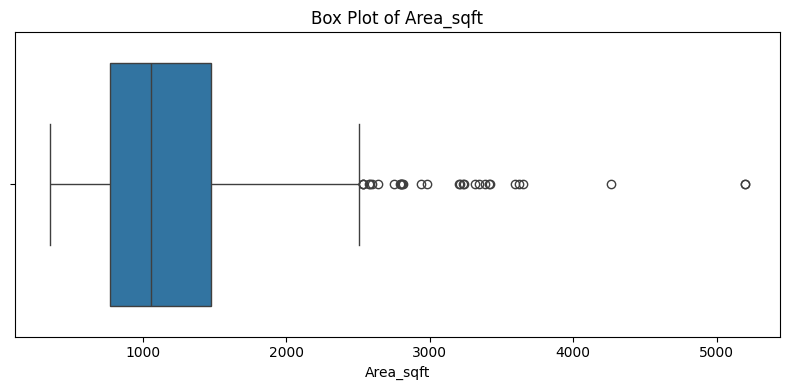

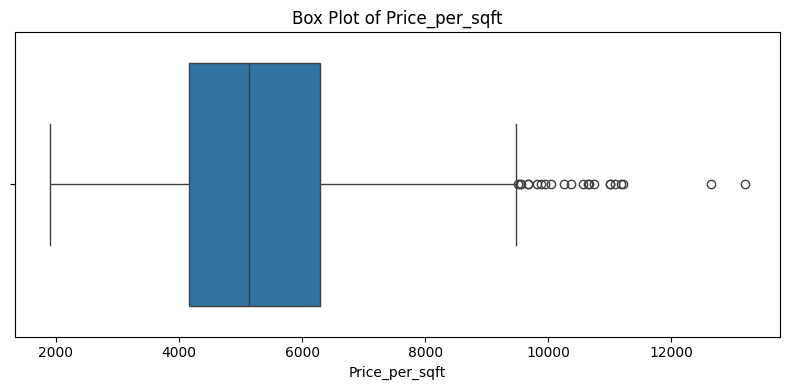

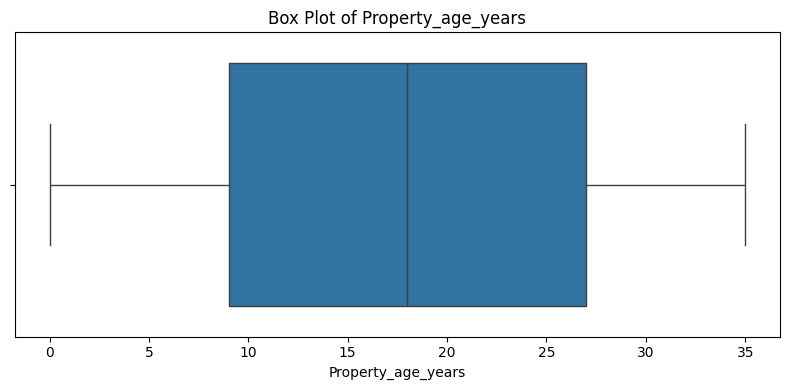

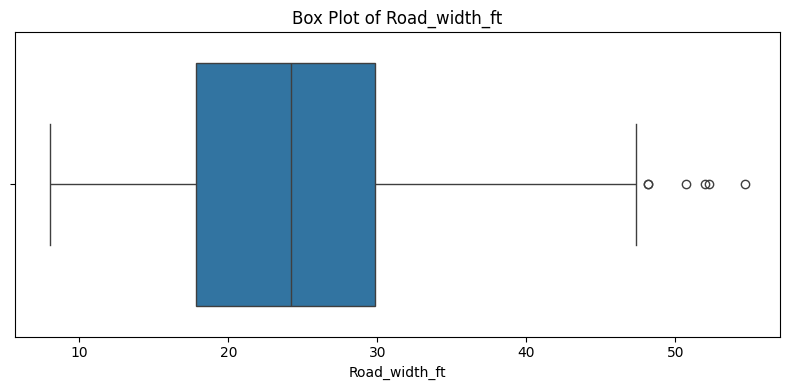

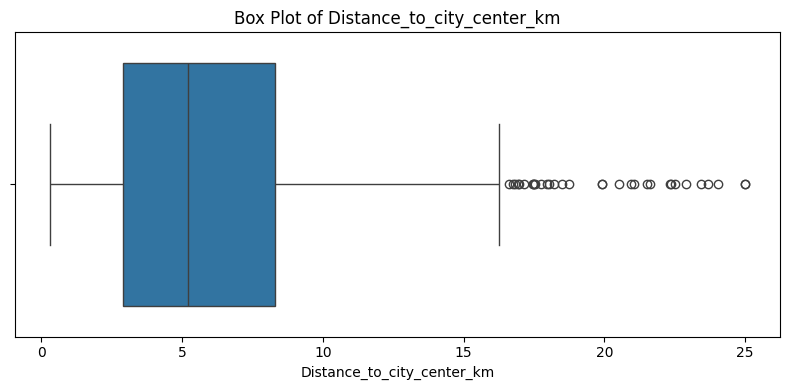

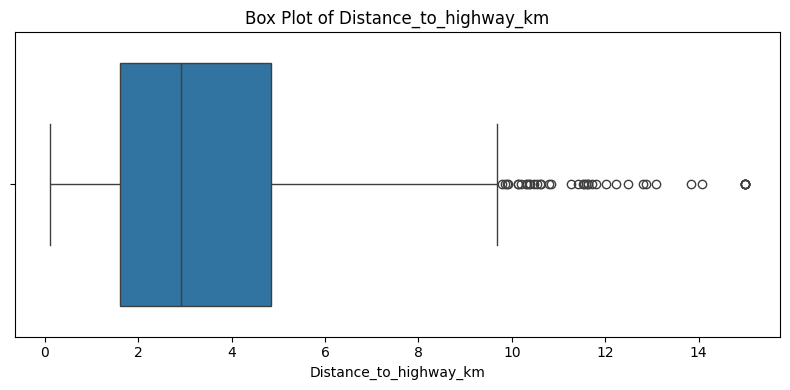

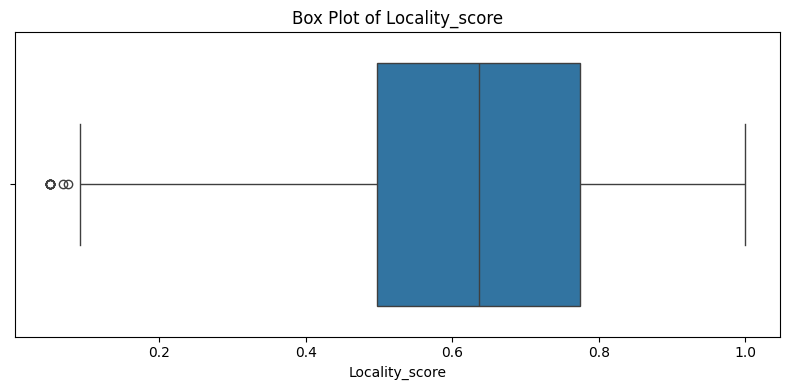

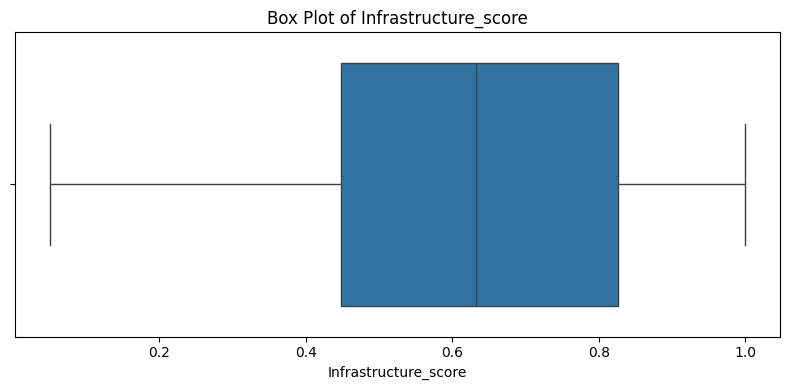

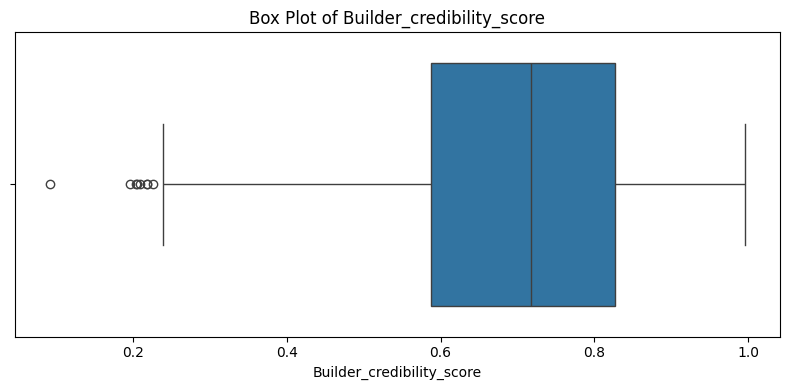

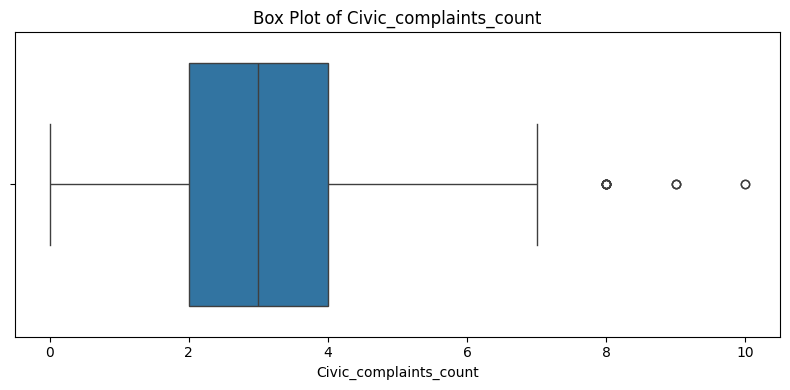

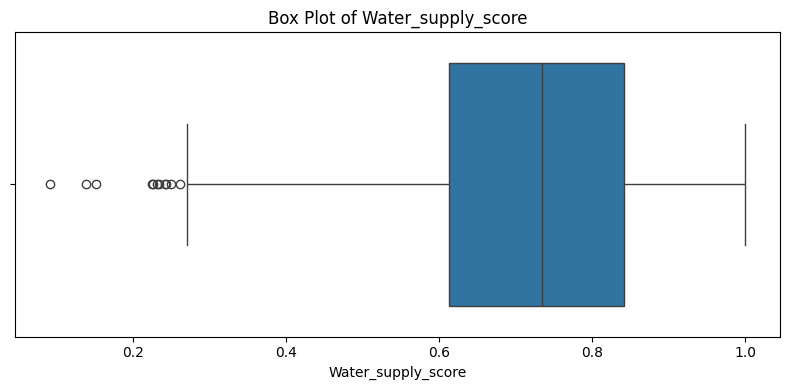

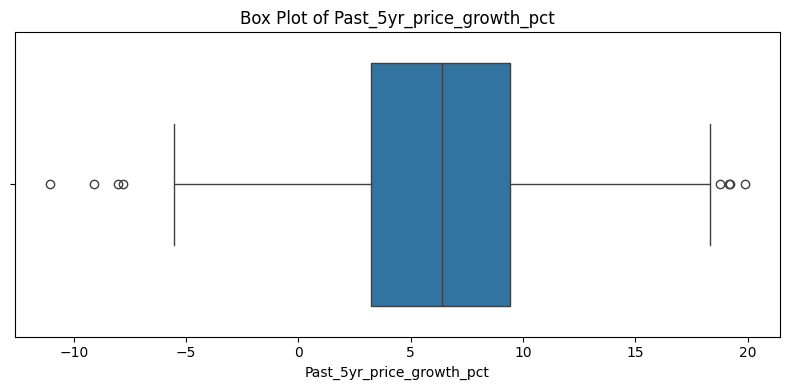

In [21]:

box_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Property_age_years",
    "Road_width_ft",
    "Distance_to_city_center_km",
    "Distance_to_highway_km",
    "Locality_score",
    "Infrastructure_score",
    "Builder_credibility_score",
    "Civic_complaints_count",
    "Water_supply_score",
    "Past_5yr_price_growth_pct"
]

for col in box_cols:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        sns.boxplot(x=df[col])
        plt.title(f"Box Plot of {col}")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()


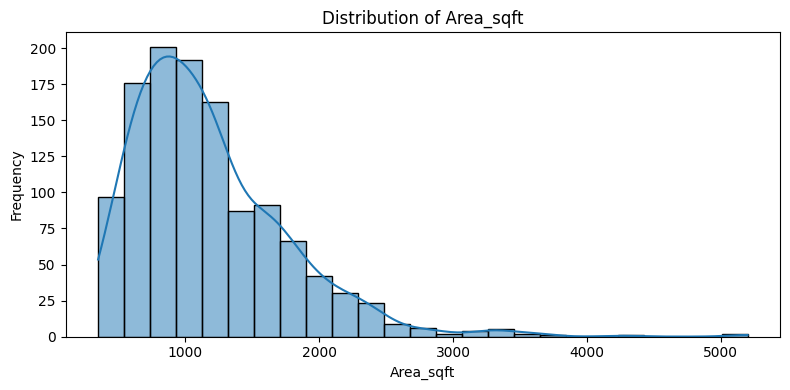

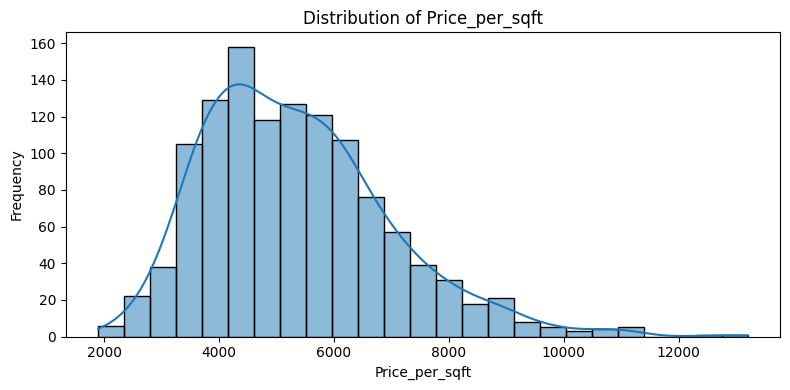

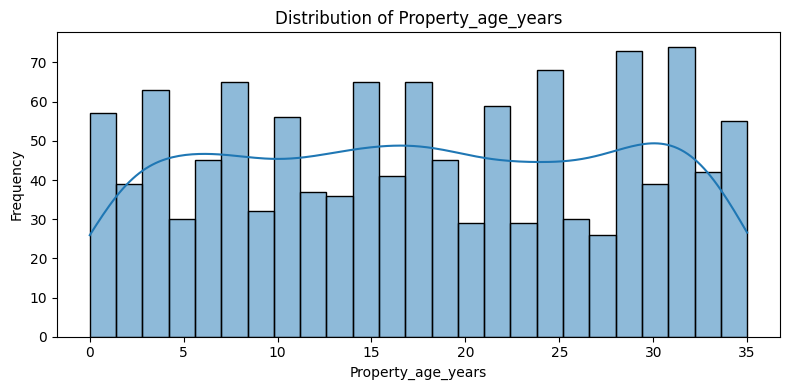

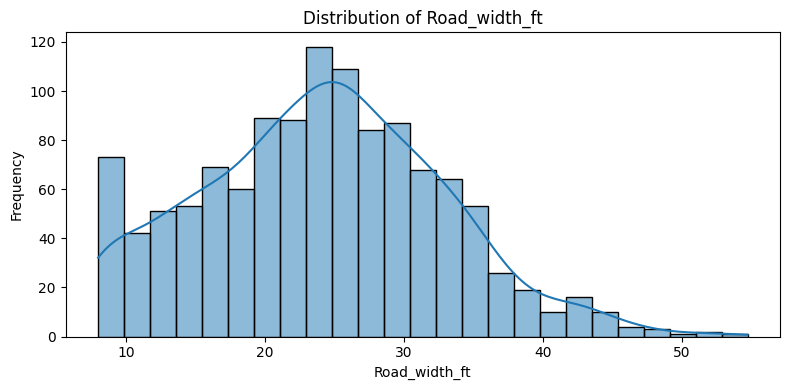

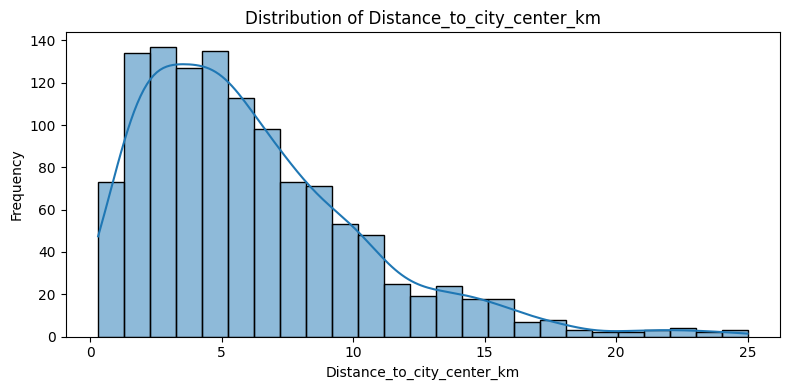

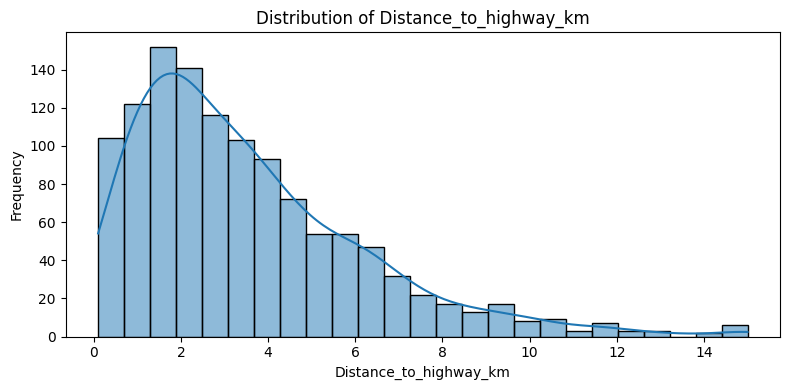

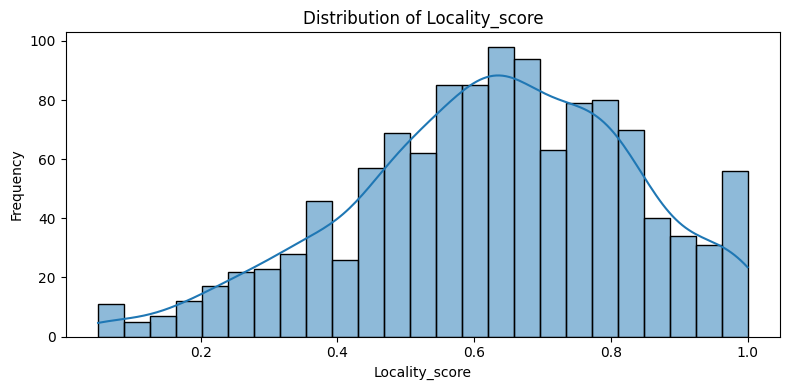

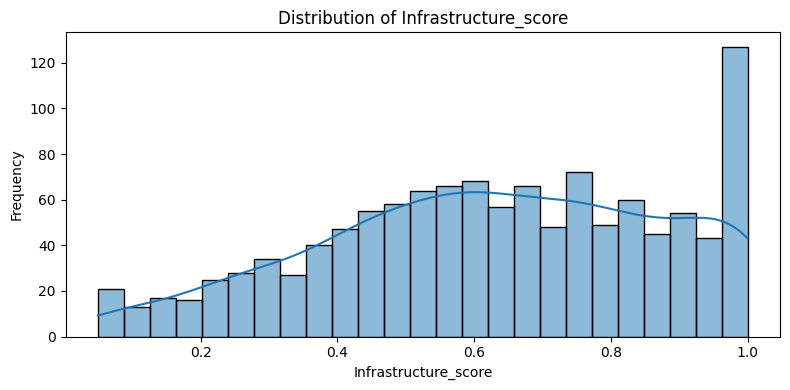

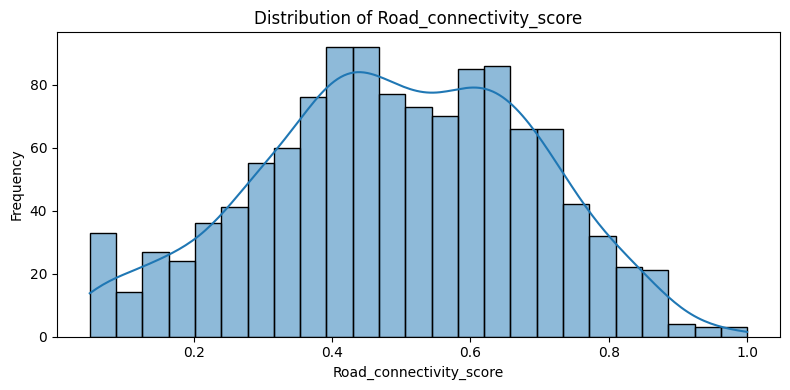

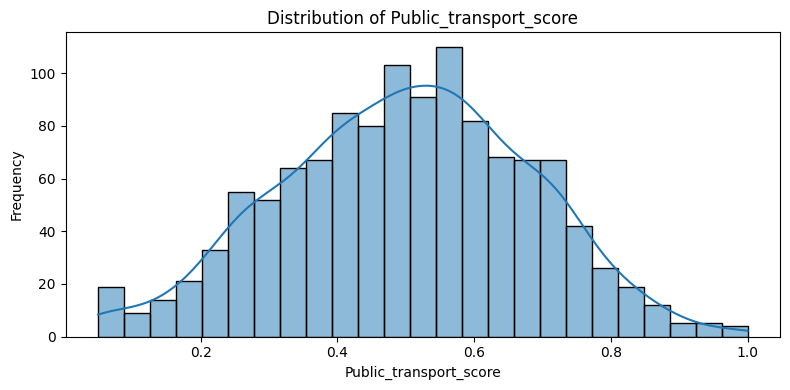

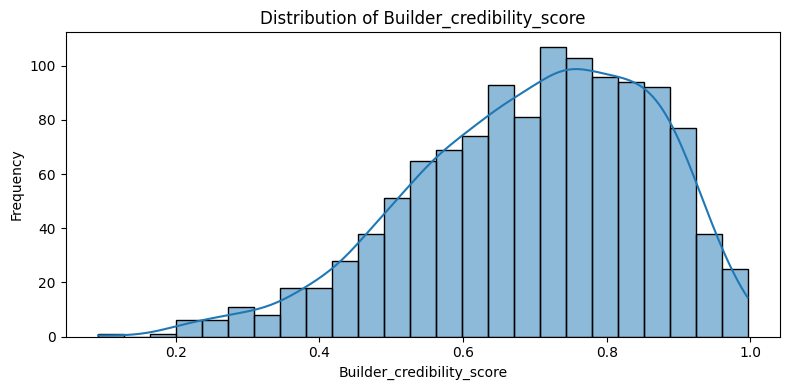

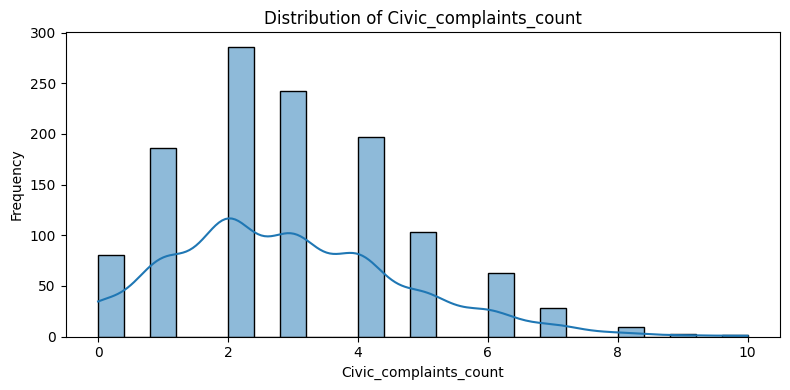

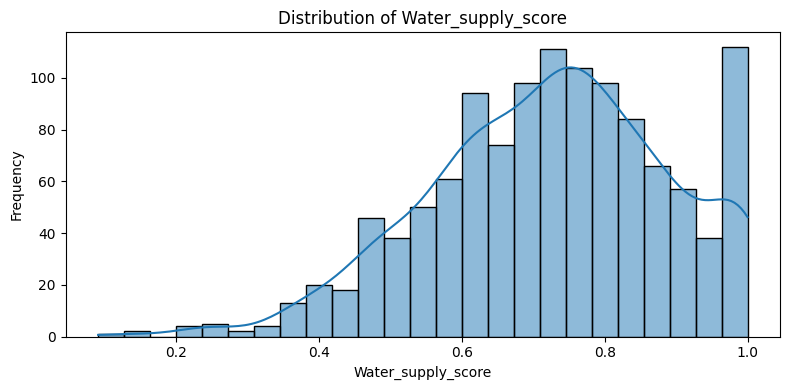

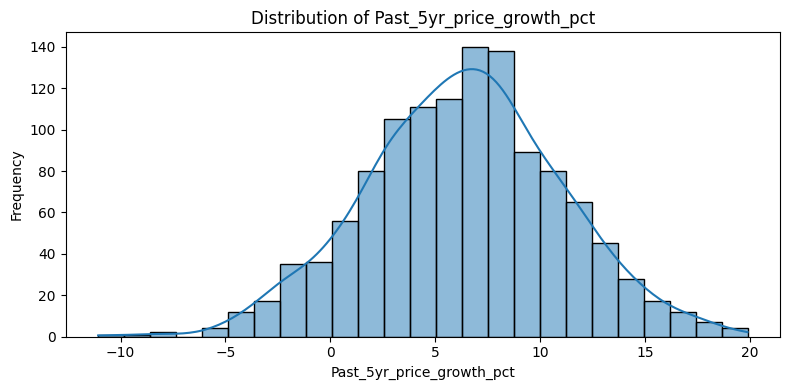

In [22]:

hist_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Property_age_years",
    "Road_width_ft",
    "Distance_to_city_center_km",
    "Distance_to_highway_km",
    "Locality_score",
    "Infrastructure_score",
    "Road_connectivity_score",
    "Public_transport_score",
    "Builder_credibility_score",
    "Civic_complaints_count",
    "Water_supply_score",
    "Past_5yr_price_growth_pct"
]

for col in hist_cols:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(df[col].dropna(), bins=25, kde=True)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()


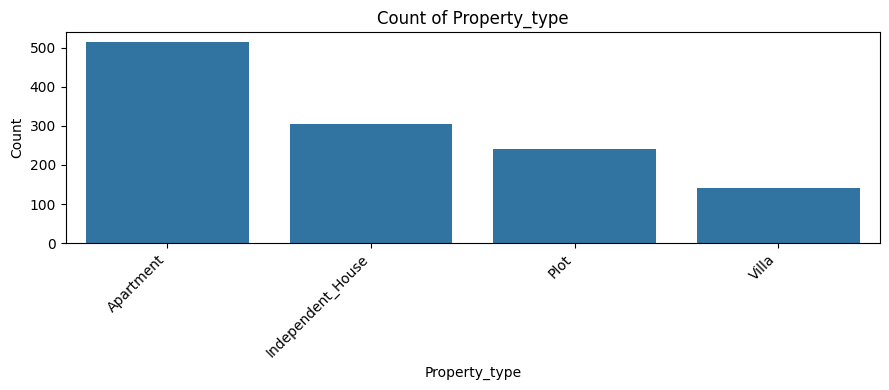

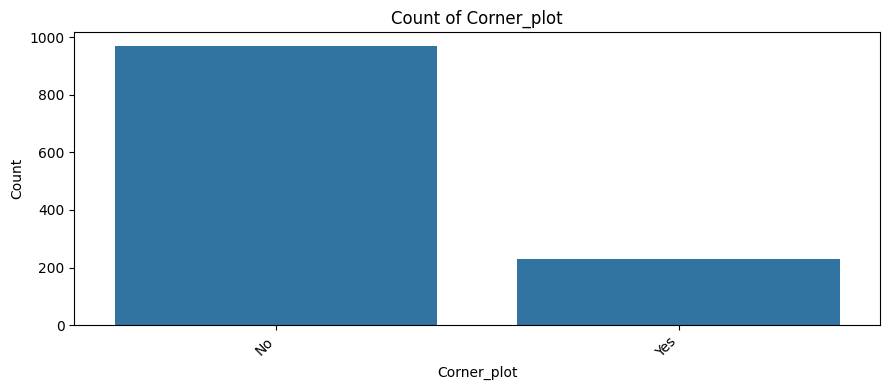

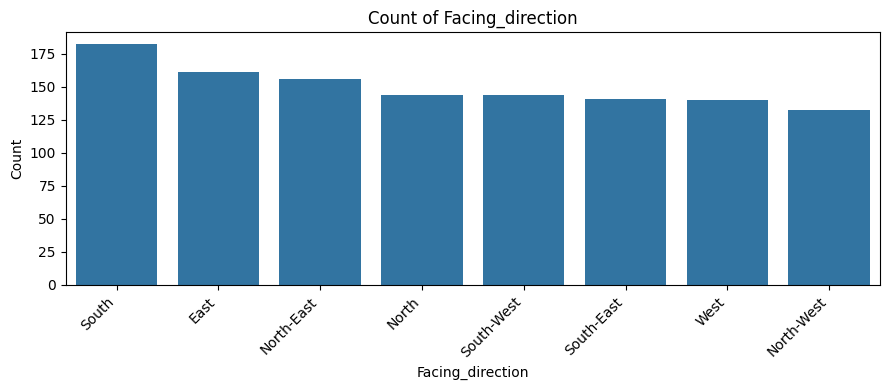

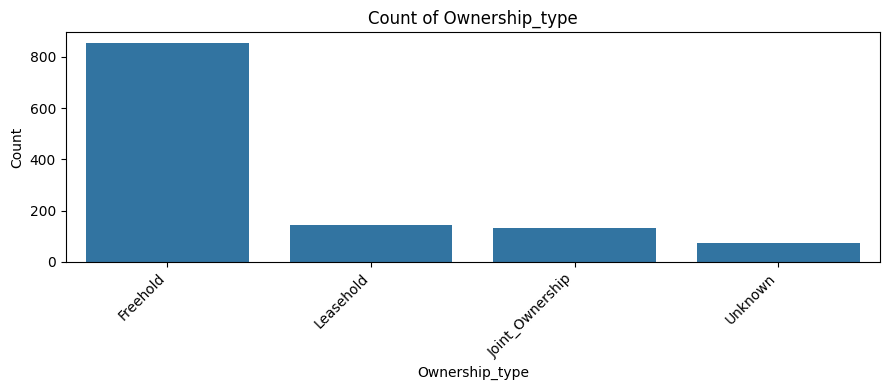

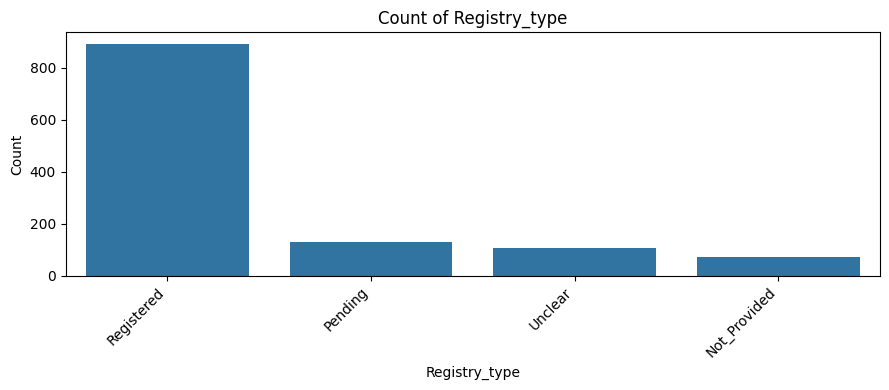

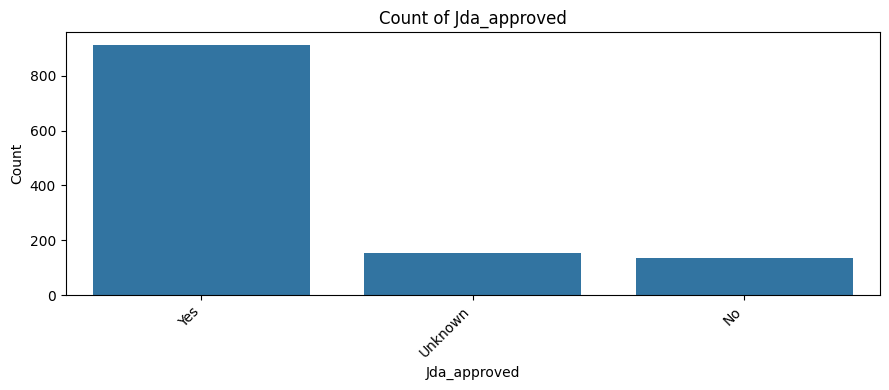

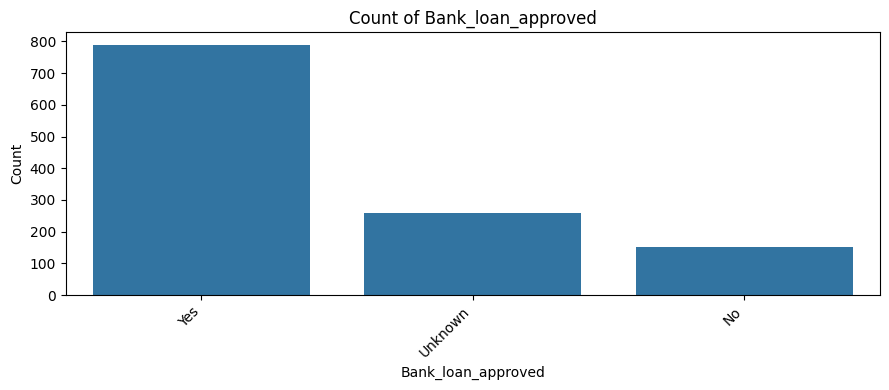

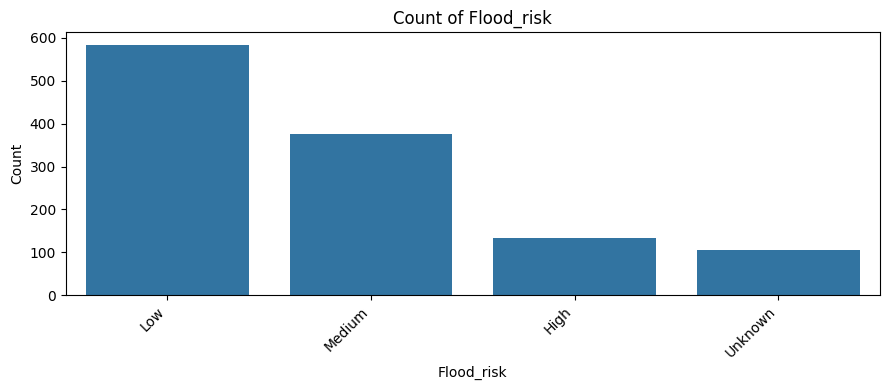

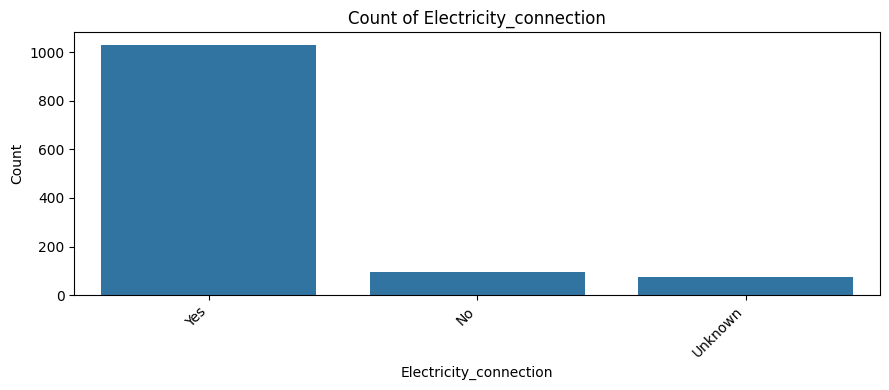

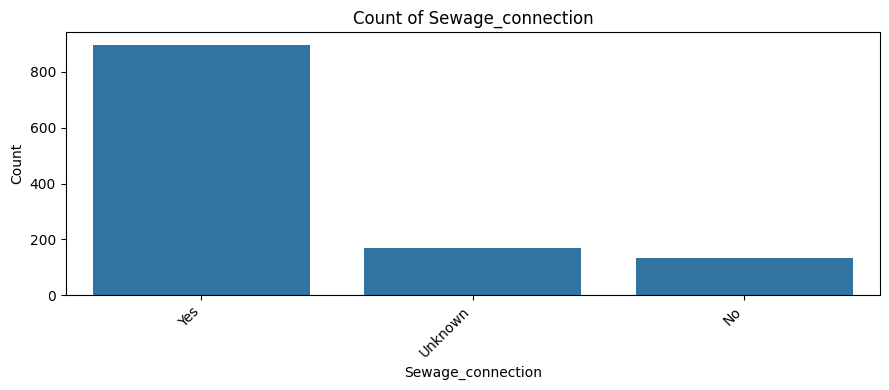

In [23]:

categorical_cols = [
    "Property_type",
    "Corner_plot",
    "Facing_direction",
    "Ownership_type",
    "Registry_type",
    "Jda_approved",
    "Bank_loan_approved",
    "Flood_risk",
    "Electricity_connection",
    "Sewage_connection"
]

for col in categorical_cols:
    if col in df.columns:
        plt.figure(figsize=(9, 4))

        order = df[col].fillna("Missing").value_counts().index

        sns.countplot(
            data=df.assign(**{col: df[col].fillna("Missing")}),
            x=col,
            order=order
        )

        plt.title(f"Count of {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()


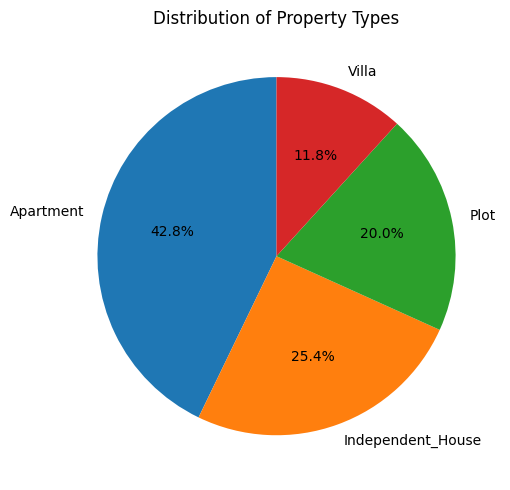

In [24]:

plt.figure(figsize=(7, 5))

df["Property_type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Property Types")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Applying Winsorization

In [25]:
import pandas as pd
import numpy as np

# Select numerical columns to check
outlier_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Property_age_years",
    "Road_width_ft",
    "Distance_to_city_center_km",
    "Distance_to_highway_km",
    "Locality_score",
    "Infrastructure_score",
    "Road_connectivity_score",
    "Public_transport_score",
    "Nearby_schools_count",
    "Nearby_hospitals_count",
    "Builder_credibility_score",
    "Civic_complaints_count",
    "Water_supply_score",
    "Past_5yr_price_growth_pct"
]

# Create a copy so the original data remains unchanged
df_clean = df.copy()

outlier_summary = []

for col in outlier_cols:
    if col not in df_clean.columns:
        continue

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count potential outliers before capping
    count_before = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    # Cap values at the IQR boundaries
    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    outlier_summary.append({
        "Column": col,
        "Outliers_Capped": int(count_before),
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)


,Column,Outliers_Capped,Lower_Bound,Upper_Bound
0,Area_sqft,30,-290.25,2531.75
1,Price_per_sqft,22,965.75,9485.75
2,Property_age_years,0,-18.00,54.00
3,Road_width_ft,6,-0.24,47.86
4,Distance_to_city_center_km,32,-5.22,16.40
5,Distance_to_highway_km,40,-3.27,9.71
6,Locality_score,11,0.08,1.19
7,Infrastructure_score,0,-0.12,1.39
8,Road_connectivity_score,0,-0.06,1.06
9,Public_transport_score,0,0.00,1.00


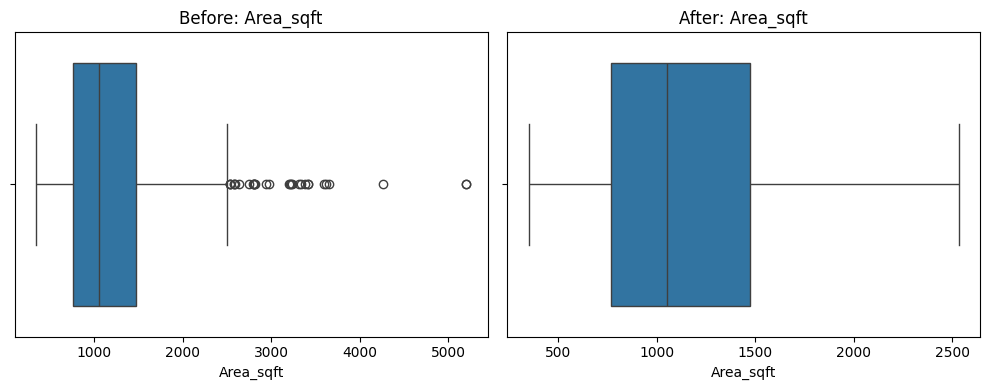

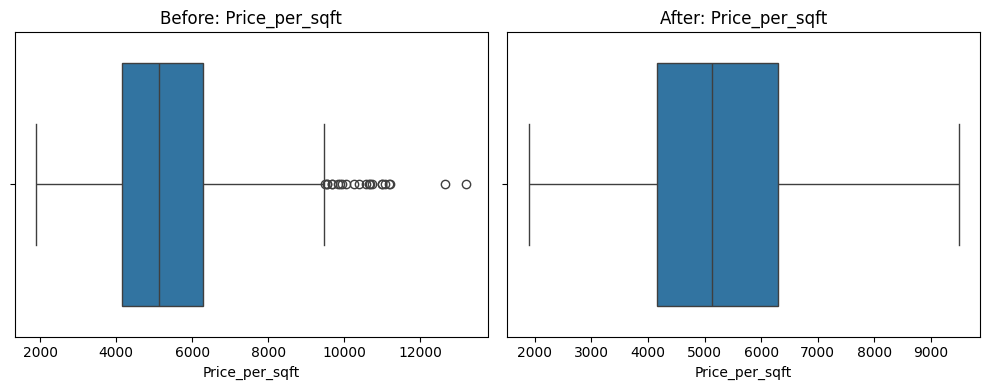

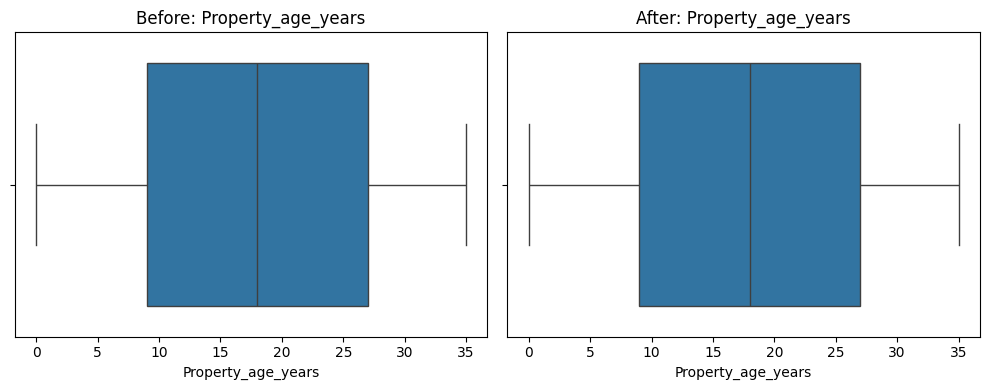

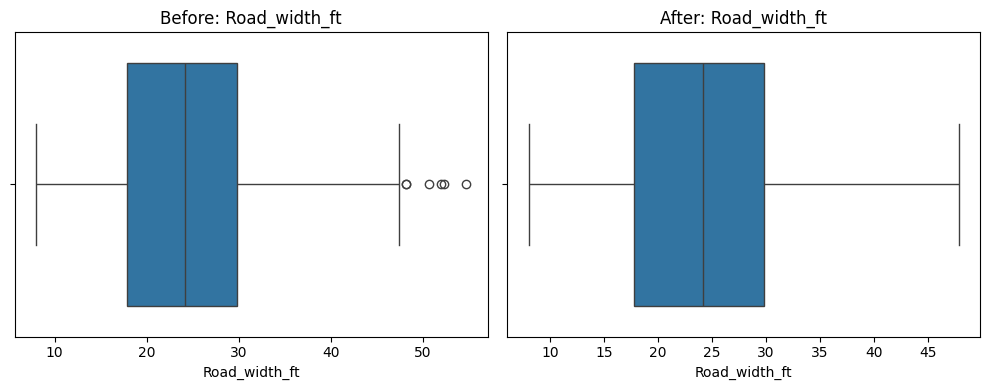

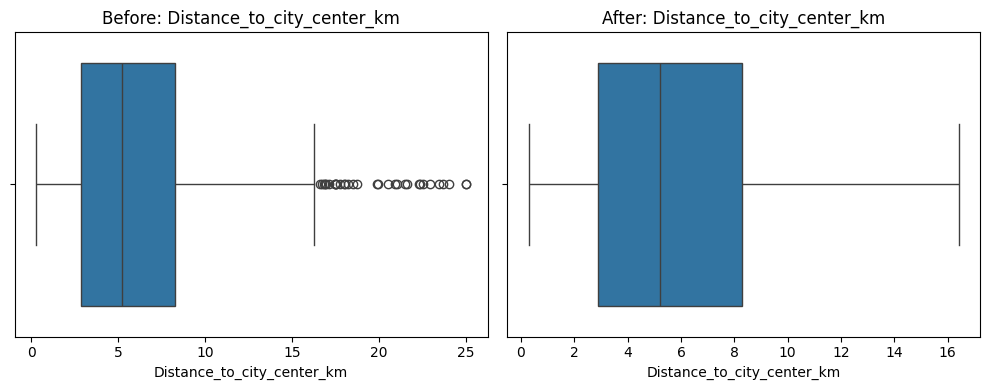

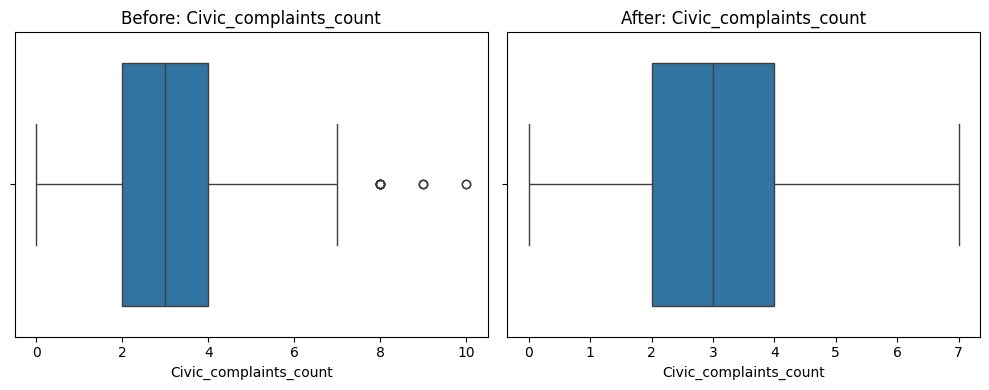

In [26]:

comparison_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Property_age_years",
    "Road_width_ft",
    "Distance_to_city_center_km",
    "Civic_complaints_count"
]

for col in comparison_cols:
    if col not in df.columns:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.boxplot(x=df[col], ax=axes[0])
    axes[0].set_title(f"Before: {col}")

    sns.boxplot(x=df_clean[col], ax=axes[1])
    axes[1].set_title(f"After: {col}")

    plt.tight_layout()
    plt.show()


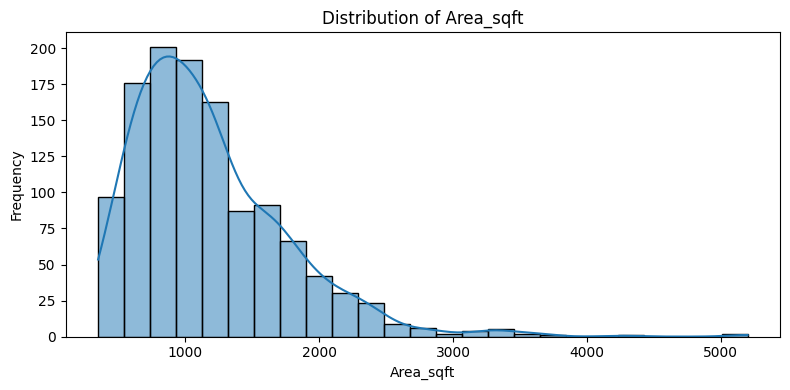

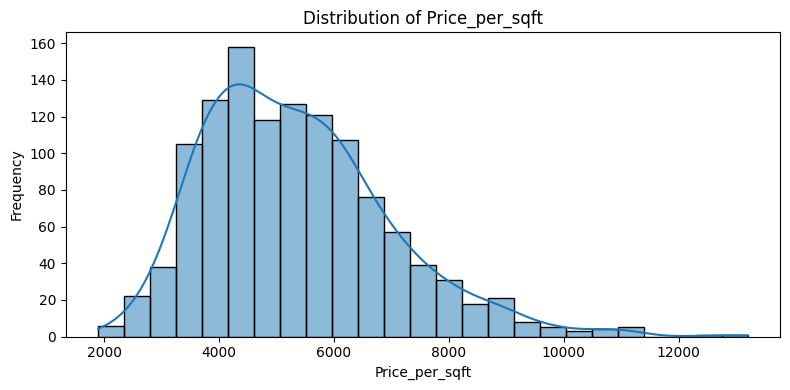

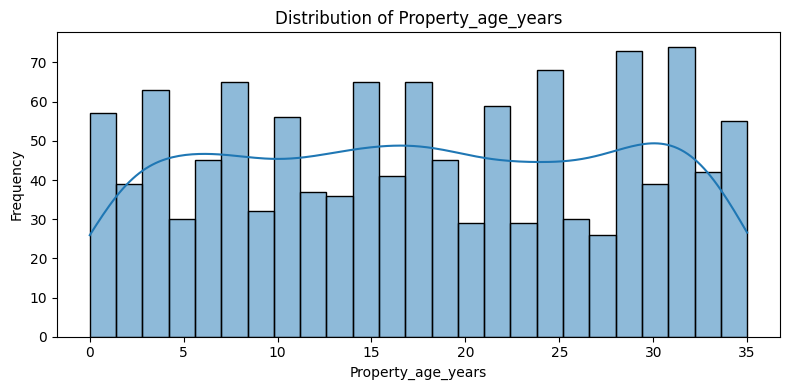

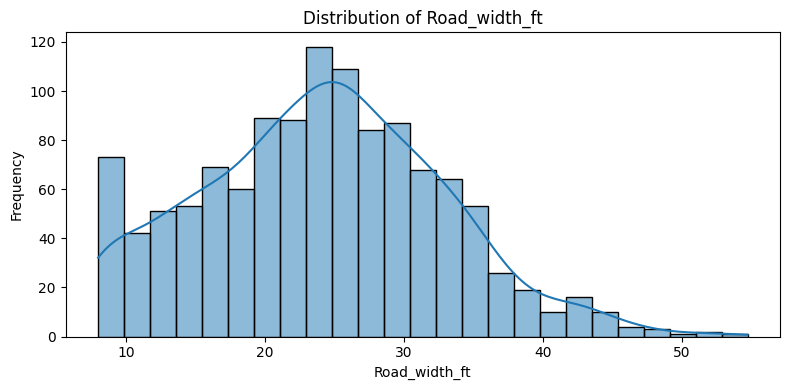

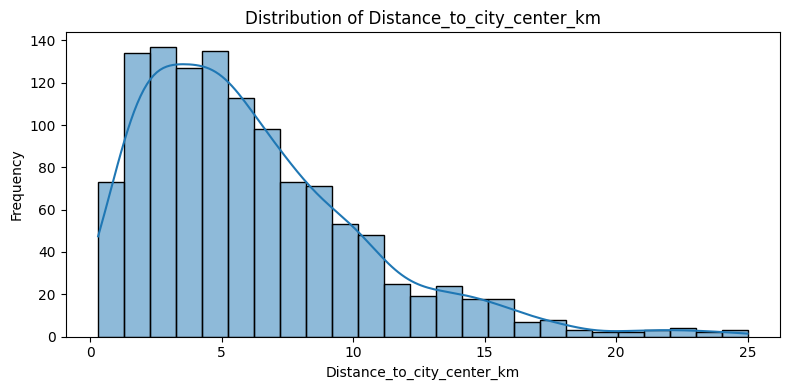

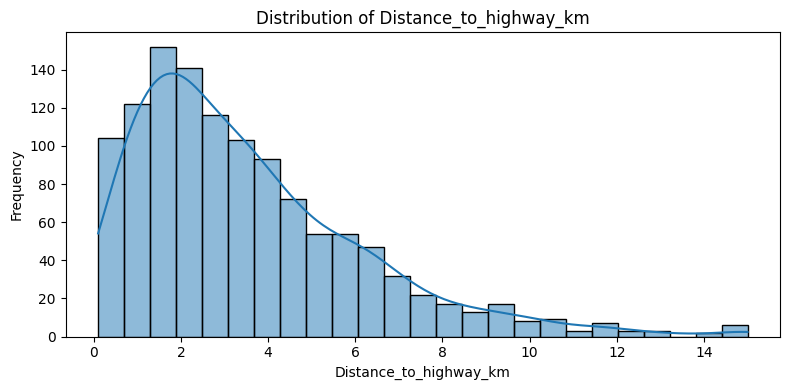

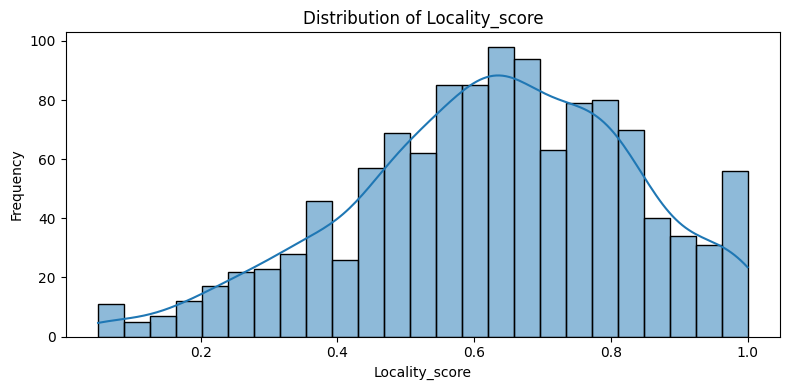

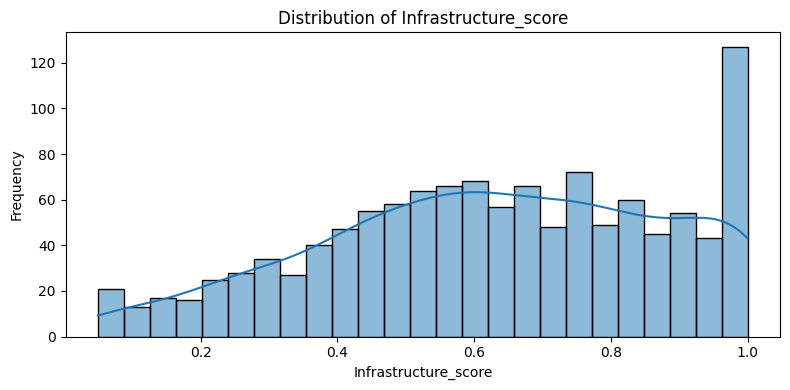

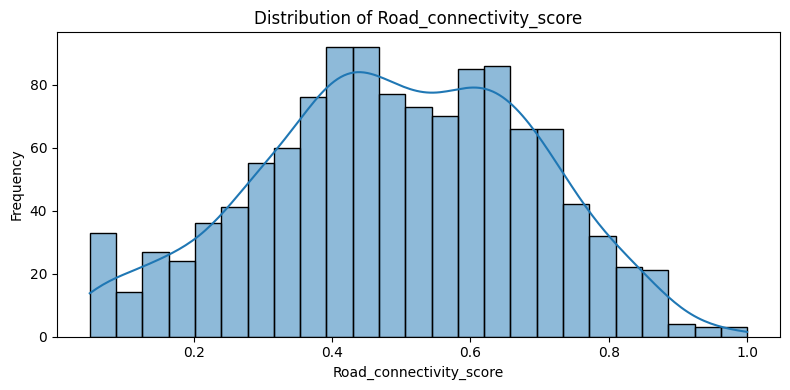

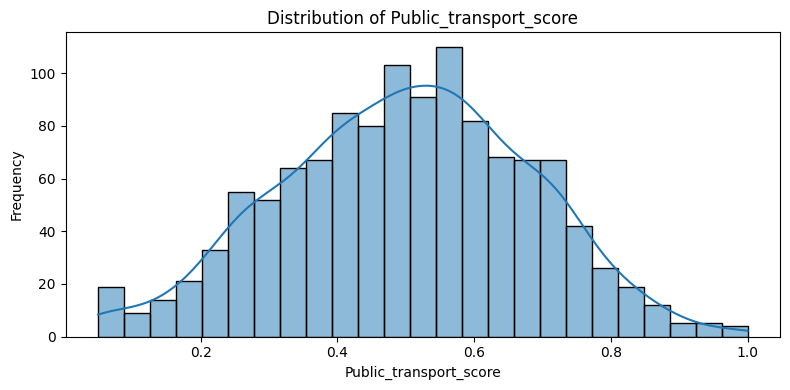

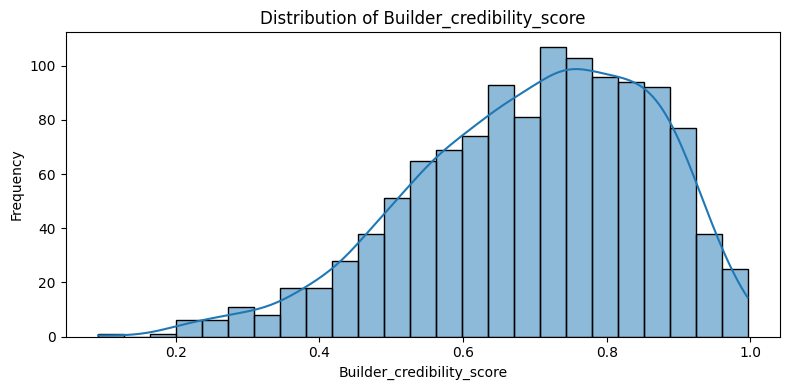

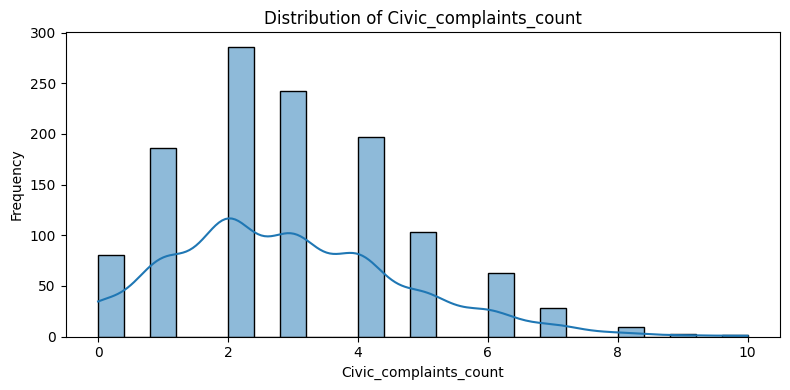

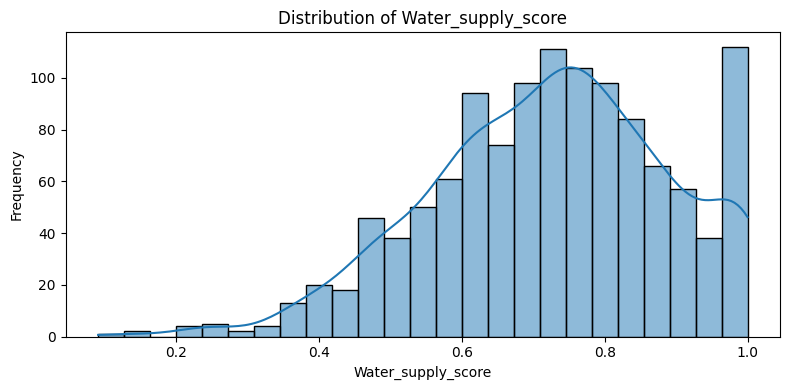

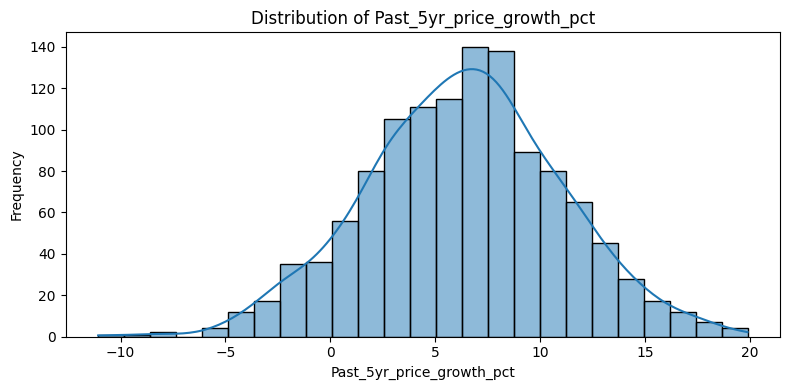

In [27]:
hist_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Property_age_years",
    "Road_width_ft",
    "Distance_to_city_center_km",
    "Distance_to_highway_km",
    "Locality_score",
    "Infrastructure_score",
    "Road_connectivity_score",
    "Public_transport_score",
    "Builder_credibility_score",
    "Civic_complaints_count",
    "Water_supply_score",
    "Past_5yr_price_growth_pct"
]

for col in hist_cols:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(df[col].dropna(), bins=25, kde=True)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()


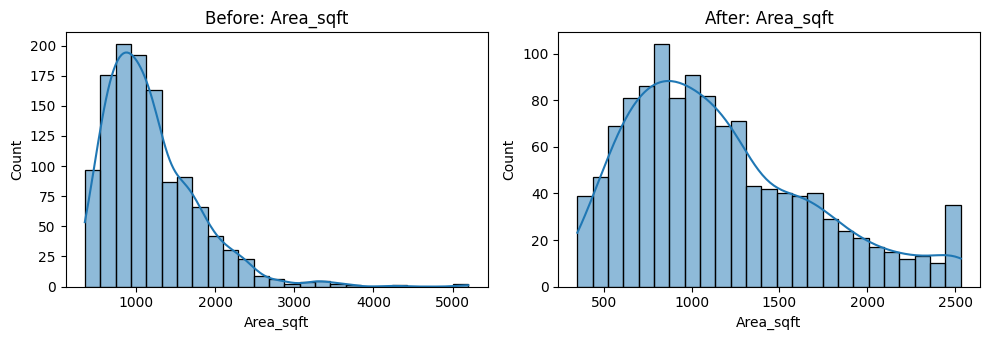

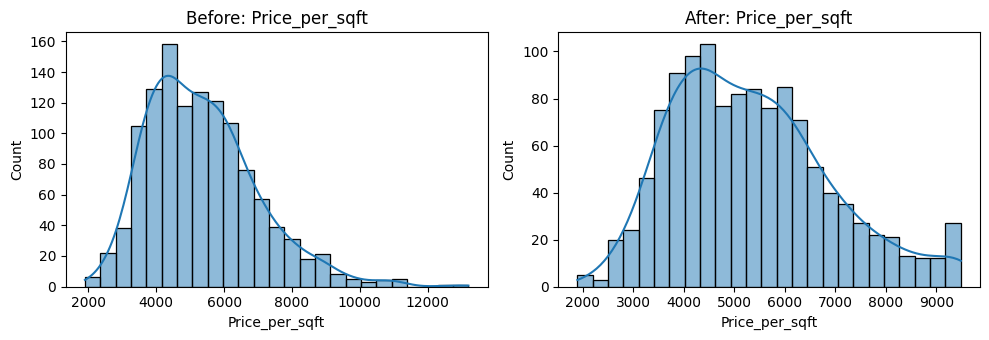

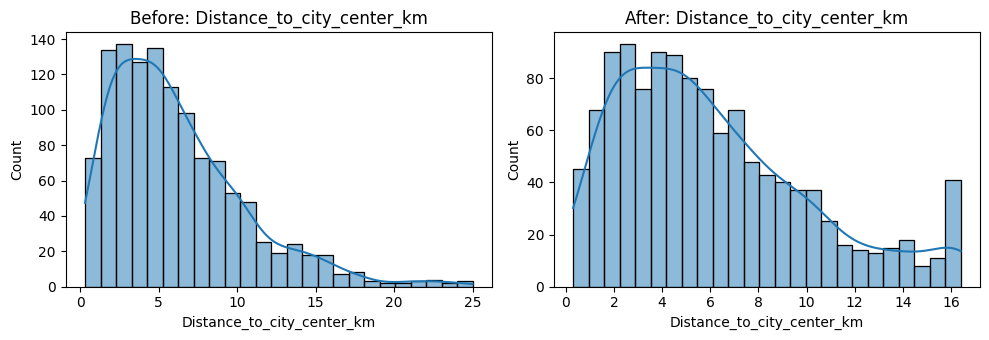

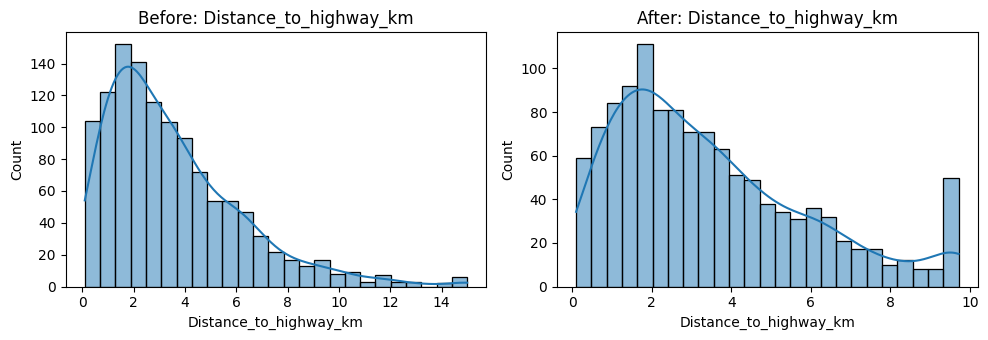

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Distance_to_city_center_km",
    "Distance_to_highway_km"
]

for col in cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

    sns.histplot(df[col].dropna(), bins=25, kde=True, ax=axes[0])
    axes[0].set_title(f"Before: {col}")

    sns.histplot(df_clean[col].dropna(), bins=25, kde=True, ax=axes[1])
    axes[1].set_title(f"After: {col}")

    plt.tight_layout()
    plt.show()


In [29]:

import numpy as np
from scipy.stats import skew

df_model = df_clean.copy()

log_cols = [
    "Area_sqft",
    "Price_per_sqft",
    "Distance_to_city_center_km",
    "Distance_to_highway_km"
]

for col in log_cols:
    # log1p requires values greater than or equal to zero
    if (df_model[col].dropna() >= 0).all():
        df_model[col + "_log"] = np.log1p(df_model[col])

# Compare skewness before and after transformation
for col in log_cols:
    print(f"\n{col}")
    print("Original skewness:", round(skew(df_model[col].dropna()), 3))
    print("Log skewness:", round(skew(df_model[col + "_log"].dropna()), 3))



Area_sqft
Original skewness: 0.8
Log skewness: -0.125

Price_per_sqft
Original skewness: 0.604
Log skewness: -0.094

Distance_to_city_center_km
Original skewness: 0.871
Log skewness: -0.28

Distance_to_highway_km
Original skewness: 0.904
Log skewness: -0.088


In [30]:

# Inspect all columns
print("Columns in dataset:")
print(df_clean.columns.tolist())

# Columns that should generally be excluded from model features
possible_leakage_cols = [
    "Property_ID",
    "Data_Generation_Seed",
    "Data_Status",
    "Asking_price_INR"
]

print("\nColumns to review:")
for col in possible_leakage_cols:
    if col in df_clean.columns:
        print(f"- {col}")


Columns in dataset:
['Property_ID', 'Property_type', 'Area_sqft', 'Price_per_sqft', 'Asking_price_INR', 'Property_age_years', 'Corner_plot', 'Facing_direction', 'Road_width_ft', 'locality', 'Distance_to_city_center_km', 'Distance_to_highway_km', 'Locality_score', 'Infrastructure_score', 'Road_connectivity_score', 'Public_transport_score', 'Nearby_schools_count', 'Nearby_hospitals_count', 'Ownership_type', 'Registry_type', 'Jda_approved', 'Bank_loan_approved', 'Builder_name', 'Builder_credibility_score', 'Civic_complaints_count', 'Flood_risk', 'Electricity_connection', 'Sewage_connection', 'Water_supply_score', 'Past_5yr_price_growth_pct', 'Recommendation', 'Target_Value_1Y_INR', 'Target_Value_3Y_INR', 'Target_Value_5Y_INR']

Columns to review:
- Property_ID
- Asking_price_INR


In [31]:

# Check duplicate rows
print("Exact duplicate rows:", df_clean.duplicated().sum())

# Check duplicate property IDs
print("Duplicate Property_IDs:",
      df_clean["Property_ID"].duplicated().sum())

# Check if asking price is derived from area and price per sq. ft.
calculated_price = (
    df_clean["Area_sqft"] * df_clean["Price_per_sqft"]
)

difference = (
    df_clean["Asking_price_INR"] - calculated_price
).abs()

print("Asking price matches area × price/sqft:",
      (difference < 1).all())


Exact duplicate rows: 0
Duplicate Property_IDs: 0
Asking price matches area × price/sqft: False


In [32]:

import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ==========================================
# STEP 1: USE YOUR CLEANED DATASET
# ==========================================
data = df_clean.copy()

# Detect recommendation column (case-insensitive)
target_matches = [
    c for c in data.columns
    if c.lower() == "recommendation"
]

if not target_matches:
    raise ValueError(
        "Recommendation column not found in df_clean."
    )

target = target_matches[0]

# Remove rows without target labels
data = data.dropna(subset=[target]).copy()

# Encode target: Buy = 1, Not Buy = 0
data[target] = (
    data[target].astype(str).str.strip().str.lower()
    .map({"buy": 1, "not buy": 0})
)

if data[target].isna().any():
    raise ValueError(
        "Unexpected recommendation labels. Check unique values."
    )

data[target] = data[target].astype(int)

# ==========================================
# STEP 2: REMOVE NON-PREDICTIVE COLUMNS
# ==========================================
exclude_cols = [
    target,
    "Property_ID",
    "Data_Status",
    "Data_Generation_Seed",
    "Asking_price_INR"
]

X = data.drop(
    columns=[c for c in exclude_cols if c in data.columns]
)
y = data[target]

# Remove columns that contain no usable values
empty_cols = X.columns[X.isna().all()].tolist()

if empty_cols:
    print("Dropping entirely empty columns:", empty_cols)
    X = X.drop(columns=empty_cols)

# Detect numerical and categorical columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

# ==========================================
# STEP 3: SPLIT BEFORE FITTING PREPROCESSING
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# ==========================================
# STEP 4: IMPUTE AND ENCODE
# ==========================================
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_cols),
    ("numerical", numerical_pipeline, numerical_cols)
])

# Learn imputation values and category mappings from training data only
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=feature_names,
    index=X_test.index
)

# ==========================================
# STEP 5: EXPORT ENCODED DATASETS
# ==========================================
train_encoded = X_train_encoded.copy()
train_encoded["recommendation"] = y_train

test_encoded = X_test_encoded.copy()
test_encoded["recommendation"] = y_test

train_encoded.to_csv("train_encoded.csv", index=False)
test_encoded.to_csv("test_encoded.csv", index=False)

# Export separate targets too, if needed
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

# Save the fitted preprocessing pipeline for future predictions
joblib.dump(preprocessor, "xgboost_preprocessor.joblib")

print("\nExport completed successfully!")
print("Training dataset shape:", train_encoded.shape)
print("Testing dataset shape:", test_encoded.shape)

print("\nTraining recommendation distribution:")
print(y_train.value_counts())

print("\nTesting recommendation distribution:")
print(y_test.value_counts())


Numerical columns: ['Area_sqft', 'Price_per_sqft', 'Property_age_years', 'Road_width_ft', 'Distance_to_city_center_km', 'Distance_to_highway_km', 'Locality_score', 'Infrastructure_score', 'Road_connectivity_score', 'Public_transport_score', 'Nearby_schools_count', 'Nearby_hospitals_count', 'Builder_credibility_score', 'Civic_complaints_count', 'Water_supply_score', 'Past_5yr_price_growth_pct', 'Target_Value_1Y_INR', 'Target_Value_3Y_INR', 'Target_Value_5Y_INR']
Categorical columns: ['Property_type', 'Corner_plot', 'Facing_direction', 'locality', 'Ownership_type', 'Registry_type', 'Jda_approved', 'Bank_loan_approved', 'Builder_name', 'Flood_risk', 'Electricity_connection', 'Sewage_connection']

Training rows: 960
Testing rows: 240

Export completed successfully!
Training dataset shape: (960, 154)
Testing dataset shape: (240, 154)

Training recommendation distribution:
Recommendation
0    789
1    171
Name: count, dtype: int64

Testing recommendation distribution:
Recommendation
0    197